# Nivel 2: ¿qué tributario trae el sedimento?
Abrir este notebook desde la carpeta del kit (la que tiene `nivel1/` y `nivel2/`). Correr las celdas en orden.

In [1]:
# carga de datos
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score as pr_auc, precision_recall_curve
from sklearn.model_selection import GroupKFold

BASE = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (parent, parent / "maipo-starter-kit")
        if (candidate / "nivel2" / "nivel2_tributarios.csv").is_file()
    ),
    None,
)
if BASE is None:
    raise FileNotFoundError(
        "No se encontró la carpeta del kit con nivel2/nivel2_tributarios.csv. "
        "Abre el notebook desde una carpeta dentro del kit."
    )

n1 = pd.read_csv(BASE / "nivel1" / "nivel1_manzano.csv", parse_dates=["fecha"])
n2 = pd.read_csv(BASE / "nivel2" / "nivel2_tributarios.csv", parse_dates=["fecha"])
df = n1.merge(n2, on="fecha")
sub = pd.read_csv(BASE / "nivel2" / "subcuencas.csv").set_index("subcuenca_id")


def carga(q, ssc):
    """Carga de sedimento en t/día (q en m3/s, ssc en mg/L)."""
    return 0.0864 * q * ssc

df.shape

(9709, 31)

## Meta 1: el Colorado aporta ~la mitad del sedimento con ~un cuarto del agua
Solo días con sedimento y caudal medidos en El Manzano **y** en el Colorado.

In [2]:
# meta 1
m = df.dropna(subset=["q_m3s", "ssc_mgL", "q_colorado_m3s", "ssc_colorado_mgL"])
frac_agua = m.q_colorado_m3s.sum() / m.q_m3s.sum()
frac_sed = carga(m.q_colorado_m3s, m.ssc_colorado_mgL).sum() / carga(m.q_m3s, m.ssc_mgL).sum()
print(f"Días en común: {len(m)} ({m.fecha.min().date()} a {m.fecha.max().date()})")
print(f"Colorado aporta {frac_agua:.1%} del agua y {frac_sed:.1%} del sedimento")

Días en común: 1124 (2003-11-21 a 2010-03-29)
Colorado aporta 24.8% del agua y 49.1% del sedimento


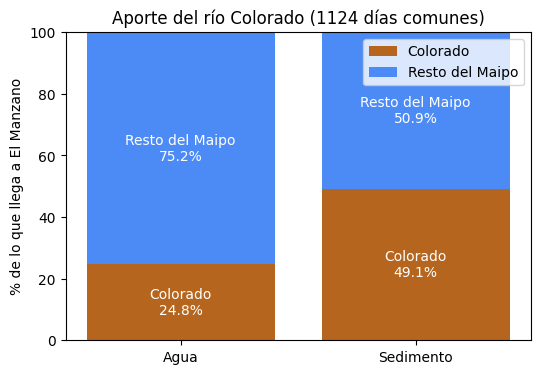

In [3]:
# meta 1: gráfico
fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Agua", "Sedimento"]
colorado = [frac_agua * 100, frac_sed * 100]
resto = [100 - value for value in colorado]
positions = range(len(labels))
ax.bar(positions, colorado, color="#B5651D", label="Colorado")
ax.bar(positions, resto, bottom=colorado, color="#4C8BF5", label="Resto del Maipo")
for x, colorado_value, resto_value in zip(positions, colorado, resto):
    ax.text(x, colorado_value / 2, f"Colorado\n{colorado_value:.1f}%", ha="center", va="center", color="white")
    ax.text(x, colorado_value + resto_value / 2, f"Resto del Maipo\n{resto_value:.1f}%", ha="center", va="center", color="white")
ax.set_xticks(list(positions), labels)
ax.set_ylabel("% de lo que llega a El Manzano")
ax.set_ylim(0, 100)
ax.set_title(f"Aporte del río Colorado ({len(m)} días comunes)")
ax.legend()
plt.show()


## Meta 2: rendimiento (t/km²/año) de las 3 estaciones con sedimento
Se calcula con todos los días de cada estación y con los días comunes a las tres (para discutir la incertidumbre).

In [4]:
# meta 2
EST = {  # subcuenca_id -> (caudal, sedimento)
    "manzano": ("q_m3s", "ssc_mgL"),
    "colorado_maipo": ("q_colorado_m3s", "ssc_colorado_mgL"),
    "san_alfonso": ("q_san_alfonso_m3s", "ssc_san_alfonso_mgL"),
}
comunes = df.dropna(subset=[c for par in EST.values() for c in par])
filas = []
for sid, (q, s) in EST.items():
    d = df.dropna(subset=[q, s])
    area = sub.loc[sid, "area_km2"]
    filas.append({
        "estacion": sid,
        "dias_ssc": len(d),
        "rend_todos_los_dias": carga(d[q], d[s]).mean() * 365 / area,
        "rend_dias_comunes": carga(comunes[q], comunes[s]).mean() * 365 / area,
    })
atrib = ["pend_media_deg", "pct_glaciar", "pct_area_sobre_4000m"]
rend = (pd.DataFrame(filas).set_index("estacion").join(sub[atrib])
        .sort_values("rend_todos_los_dias", ascending=False).round(1))
print(f"Días comunes a las 3 estaciones: {len(comunes)}")
rend

Días comunes a las 3 estaciones: 356


,dias_ssc,rend_todos_los_dias,rend_dias_comunes,pend_media_deg,pct_glaciar,pct_area_sobre_4000m
estacion,,,,,,
colorado_maipo,1391,794.4,963.2,28.6,9.1,29.3
manzano,5237,391.1,622.1,28.0,7.2,16.5
san_alfonso,624,255.6,290.5,28.1,7.0,11.2


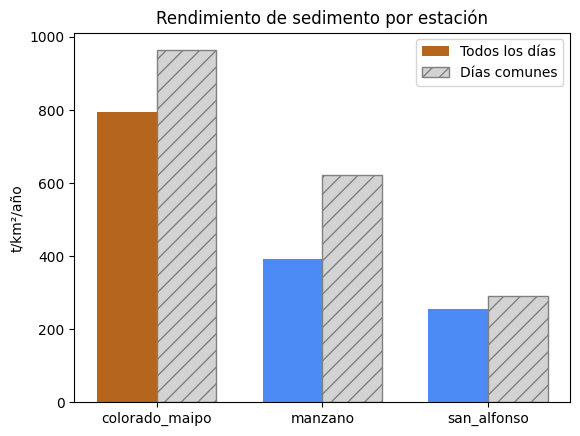

In [5]:
# meta 2: gráfico
estaciones = list(rend.index)
positions = list(range(len(estaciones)))
width = 0.36
colores_estacion = ["#B5651D" if sid == "colorado_maipo" else "#4C8BF5" for sid in estaciones]
ax = plt.gca()
ax.clear()
ax.bar([i - width / 2 for i in positions], rend["rend_todos_los_dias"], width=width,
       color=colores_estacion, label="Todos los días")
ax.bar([i + width / 2 for i in positions], rend["rend_dias_comunes"], width=width,
       color="#D3D3D3", edgecolor="#808080", hatch="//", label="Días comunes")
ax.set_xticks(positions, estaciones, rotation=0)
ax.set_ylabel("t/km²/año")
ax.set_title("Rendimiento de sedimento por estación")
ax.legend()
plt.show()


## Meta 3: ranking de subcuencas sin sedimento medido
Colorado vs San Alfonso: la pendiente es casi igual; lo que cambia es el % del área sobre 4.000 m (y el % glaciar). Se ordena por esos dos atributos.

Ojo con `drena_a`: `hualtatas` está dentro de `melosas` y `echaurren` dentro de `yeso_residuo`. Rankearlas junto a su unidad madre contaría el mismo terreno dos veces, así que el ranking usa solo las 7 unidades sin solape (junto a las medidas suman el área de El Manzano) y las anidadas se muestran aparte.

In [6]:
# meta 3
# ponytail: ranking por altura + desempate glaciar; pasar a un índice ponderado
# solo si aparecen más estaciones con SSC para calibrar los pesos.
cols_rank = ["drena_a", "area_km2", "elev_media_m", *atrib, "geologia"]
sin_ssc = sub[sub.tiene_ssc == 0]
anidadas = sin_ssc[sin_ssc.drena_a.isin(sin_ssc.index)]  # drenan a otra subcuenca sin SSC
ranking = (sin_ssc.drop(anidadas.index)
           .sort_values(["pct_area_sobre_4000m", "pct_glaciar"], ascending=False)[cols_rank])
ranking.insert(0, "rank", range(1, len(ranking) + 1))
# las 7 unidades sin solape cubren todo El Manzano: nada contado dos veces, nada fuera
assert abs(ranking.area_km2.sum() - sub.loc["manzano", "area_km2"]) < 1
display(ranking)
anidadas[cols_rank]  # detalle dentro de su unidad madre (drena_a), no compiten en el ranking

,rank,drena_a,area_km2,elev_media_m,pend_media_deg,pct_glaciar,pct_area_sobre_4000m,geologia
subcuenca_id,,,,,,,,
olivares,1,colorado_maipo,541.5,3688.0,28.8,14.3,39.4,volcánica ácida
colorado_alto,2,colorado_maipo,783.3,3733.0,29.6,9.5,34.8,sedimentaria carbonatada
volcan,3,san_alfonso,523.4,3368.0,28.3,14.2,18.6,sedimentaria mixta
yeso_residuo,4,san_alfonso,800.6,3084.0,26.9,5.3,12.6,sedimentaria mixta
melosas,5,san_alfonso,1462.7,3192.0,28.6,5.4,7.8,sedimentaria mixta
colorado_bajo_residuo,6,colorado_maipo,337.9,2248.0,26.2,0.0,0.1,volcánica ácida
manzano_local_residuo,7,manzano,389.5,2092.0,25.0,0.0,0.0,volcánica ácida


,drena_a,area_km2,elev_media_m,pend_media_deg,pct_glaciar,pct_area_sobre_4000m,geologia
subcuenca_id,,,,,,,
hualtatas,melosas,1035.5,3320.0,28.5,7.6,10.7,sedimentaria mixta
echaurren,yeso_residuo,32.6,3591.0,26.7,3.2,12.8,volcánica ácida


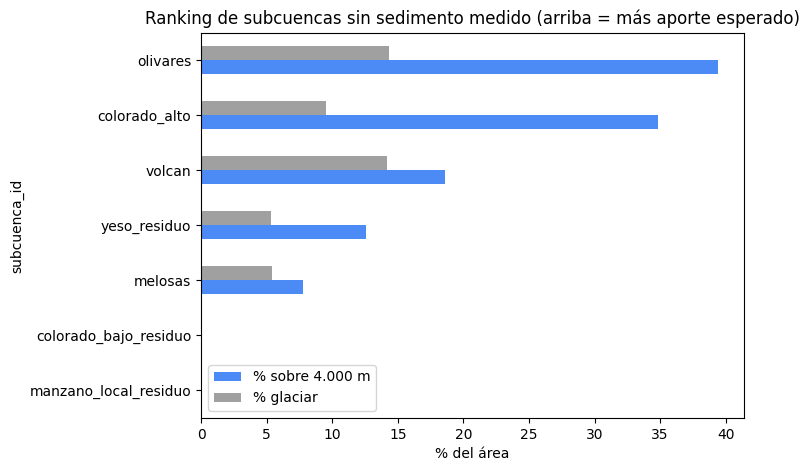

In [7]:
# meta 3: gráfico (% sobre 4000 m y % glaciar de cada subcuenca sin SSC)
ax = ranking[["pct_area_sobre_4000m", "pct_glaciar"]].iloc[::-1].plot.barh(
    figsize=(7, 5), color=["#4C8BF5", "#A0A0A0"])
ax.set_xlabel("% del área")
ax.set_title("Ranking de subcuencas sin sedimento medido (arriba = más aporte esperado)")
ax.legend(["% sobre 4.000 m", "% glaciar"])
plt.show()


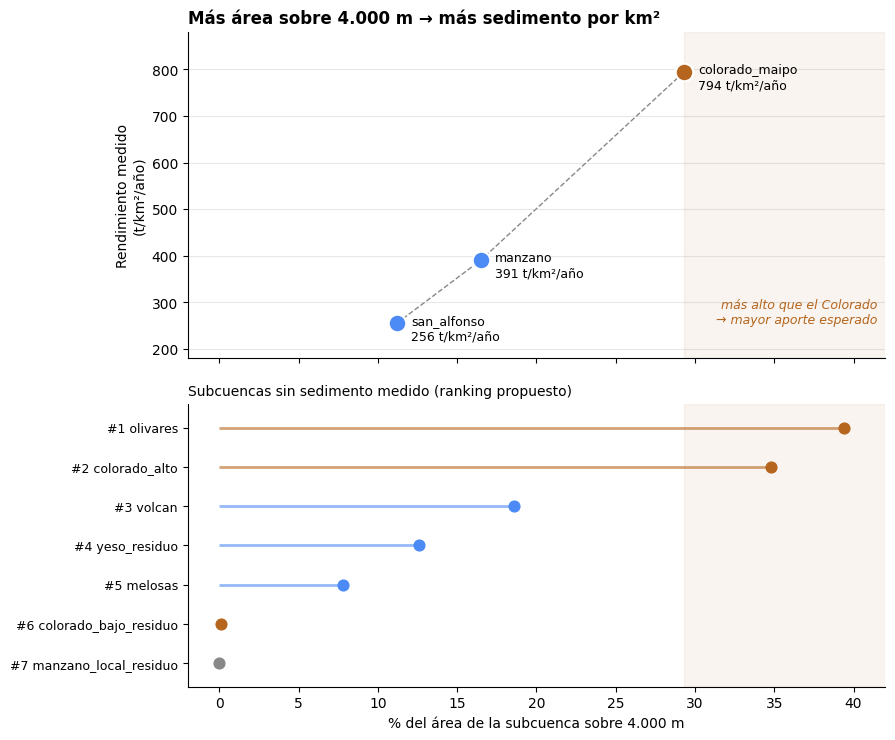

In [8]:
# meta 2 y 3: rendimiento vs altura
CAFE, AZUL, GRIS = "#B5651D", "#4C8BF5", "#888888"
color = lambda sid, drena: CAFE if "colorado" in (sid + str(drena)) else (GRIS if drena == "manzano" else AZUL)

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 8.5), sharex=True,
                              gridspec_kw={"height_ratios": [3, 2.6], "hspace": 0.15})

# arriba: estaciones medidas + tendencia
x, y = rend.pct_area_sobre_4000m, rend.rend_todos_los_dias
ax.plot(x.sort_values(), y[x.sort_values().index], ls="--", color=GRIS, lw=1, zorder=1)
for sid in rend.index:
    ax.scatter(x[sid], y[sid], s=160, color=color(sid, ""), edgecolor="white", lw=1.5, zorder=3)
    ax.annotate(f"{sid}\n{y[sid]:.0f} t/km²/año", (x[sid], y[sid]), xytext=(10, -4),
                textcoords="offset points", fontsize=9, va="center")
ax.axvspan(x.max(), 42, color=CAFE, alpha=0.07)
ax.text(41.5, y.min(), "más alto que el Colorado\n→ mayor aporte esperado", ha="right",
        fontsize=9, color=CAFE, style="italic")
ax.set_ylim(180, 880)
ax.set_ylabel("Rendimiento medido\n(t/km²/año)")
ax.set_title("Más área sobre 4.000 m → más sedimento por km²", loc="left", fontsize=12, weight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

# abajo: subcuencas sin medición, una fila por subcuenca (ordenadas por ranking)
filas = ranking.iloc[::-1]
for j, (sid, r) in enumerate(filas.iterrows()):
    c = color(sid, r.drena_a)
    ax2.hlines(j, 0, r.pct_area_sobre_4000m, color=c, lw=2, alpha=0.6)
    ax2.scatter(r.pct_area_sobre_4000m, j, s=60, color=c, zorder=3)
ax2.set_yticks(range(len(filas)), [f"#{r} {s}" for s, r in filas["rank"].items()], fontsize=9)
ax2.axvspan(x.max(), 42, color=CAFE, alpha=0.07)
ax2.set_ylim(-0.6, len(filas) - 0.4)
ax2.spines[["top", "right"]].set_visible(False)
ax2.set_title("Subcuencas sin sedimento medido (ranking propuesto)", loc="left", fontsize=10)
ax2.set_xlabel("% del área de la subcuenca sobre 4.000 m")
ax2.set_xlim(-2, 42)
plt.show()

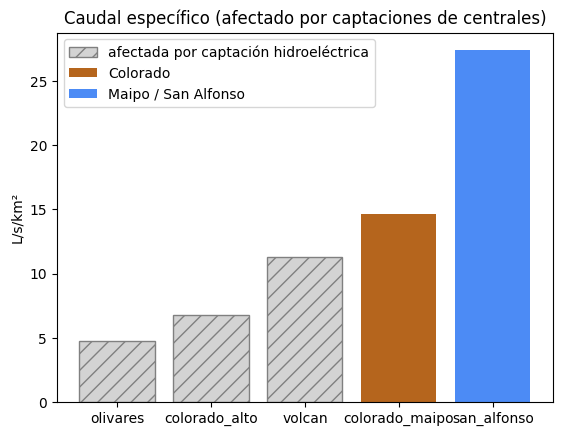

In [9]:
# meta 3: trampa de la guía, caudal por km2 subestimado por captaciones hidroeléctricas
# NO usar para rankear
esp = pd.Series({sid: df[col].mean() / sub.loc[sid, "area_km2"] * 1000 for col, sid in [
    ("q_olivares_m3s", "olivares"), ("q_colorado_alto_m3s", "colorado_alto"),
    ("q_volcan_m3s", "volcan"), ("q_colorado_m3s", "colorado_maipo"),
    ("q_san_alfonso_m3s", "san_alfonso")]})
ax = plt.gca()
ax.clear()
captadas = ["olivares", "colorado_alto", "volcan"]
ax.bar(range(3), esp.loc[captadas], color="#D3D3D3", edgecolor="#808080", hatch="//",
       label="afectada por captación hidroeléctrica")
ax.bar(3, esp.loc["colorado_maipo"], color="#B5651D", label="Colorado")
ax.bar(4, esp.loc["san_alfonso"], color="#4C8BF5", label="Maipo / San Alfonso")
ax.set_xticks(range(len(esp)), esp.index, rotation=0)
ax.set_ylabel("L/s/km²")
ax.set_title("Caudal específico (afectado por captaciones de centrales)")
ax.legend()
plt.show()

## Meta 4: modelo de ML vs regla `p_liq_48h_mm` (PR-AUC, prueba `anio_hidro` 2013–2018)
Objetivo: 1 si `ssc_mgL` supera el percentil 95 (calculado solo con entrenamiento). Sin columnas de sedimento ni de eventos en X.

In [10]:
# meta 4: datos y partición temporal
FEATS = ["q_m3s", "q_colorado_m3s", "q_volcan_m3s", "q_olivares_m3s", "q_colorado_alto_m3s",
         "p_liq_mm", "p_liq_48h_mm", "p_acum3d_mm", "p_liq_colorado_mm", "p_liq_san_alfonso_mm",
         "iso0_m", "frac_bajo_iso0", "t_media_C", "mes"]
t = df[df.ssc_mgL.notna()]
# año hidrológico abr–mar: un mismo verano (dic–mar) no se parte entre train y test
anio = t.anio_hidro
train, test = t[anio <= 2012], t[(anio >= 2013) & (anio <= 2018)]
umbral = train.ssc_mgL.quantile(0.95)
y_tr, y_te = (train.ssc_mgL > umbral).astype(int), (test.ssc_mgL > umbral).astype(int)
print(f"Umbral p95 (train): {umbral:.0f} mg/L | positivos train {y_tr.sum()}/{len(y_tr)}, "
      f"test {y_te.sum()}/{len(y_te)} (prevalencia {y_te.mean():.3f})")

Umbral p95 (train): 1656 mg/L | positivos train 168/3358, test 77/1900 (prevalencia 0.041)


In [11]:
# meta 4: elegir algoritmo sin mirar el test (GroupKFold por anio_hidro dentro de train)
# min_samples_leaf=5: hojas con al menos 5 días, para no memorizar días sueltos (solo ~5% son eventos)
RF = dict(n_estimators=500, min_samples_leaf=5, random_state=0, n_jobs=-1)


def pr_auc_cv(clf, feats):
    """PR-AUC promedio en 5 folds; cada año hidrológico queda entero en un solo fold."""
    folds = GroupKFold(n_splits=5).split(train, y_tr, groups=train.anio_hidro)
    return pd.Series([pr_auc(y_tr.iloc[va], clf.fit(train[feats].iloc[tr], y_tr.iloc[tr])
                             .predict_proba(train[feats].iloc[va])[:, 1]) for tr, va in folds]).mean()


# q_m3s es el caudal medio del mismo día en El Manzano: incluye horas posteriores a la muestra
# de las 08:00 (nowcast). Se prueba sin él para ver si el modelo depende de esa variable.
cv = pd.Series({
    "RF": pr_auc_cv(RandomForestClassifier(**RF), FEATS),
    "HGB": pr_auc_cv(HistGradientBoostingClassifier(random_state=0), FEATS),
    "RF sin q_m3s": pr_auc_cv(RandomForestClassifier(**RF), [f for f in FEATS if f != "q_m3s"]),
    "RF class_weight='balanced'": pr_auc_cv(RandomForestClassifier(**RF, class_weight="balanced"), FEATS),
})
print("PR-AUC validación cruzada (solo train):")
print(cv.round(3).to_string())


PR-AUC validación cruzada (solo train):
RF                            0.184
HGB                           0.176
RF sin q_m3s                  0.215
RF class_weight='balanced'    0.166


In [12]:
# meta 4: entrenamiento y PR-AUC
modelo = RandomForestClassifier(**RF)
modelo.fit(train[FEATS], y_tr)  # sklearn >= 1.4 acepta NaN
prob = modelo.predict_proba(test[FEATS])[:, 1]
regla = test.p_liq_48h_mm.fillna(0)
print(f"PR-AUC modelo: {pr_auc(y_te, prob):.3f} | regla p_liq_48h_mm: {pr_auc(y_te, regla):.3f}")

PR-AUC modelo: 0.127 | regla p_liq_48h_mm: 0.035


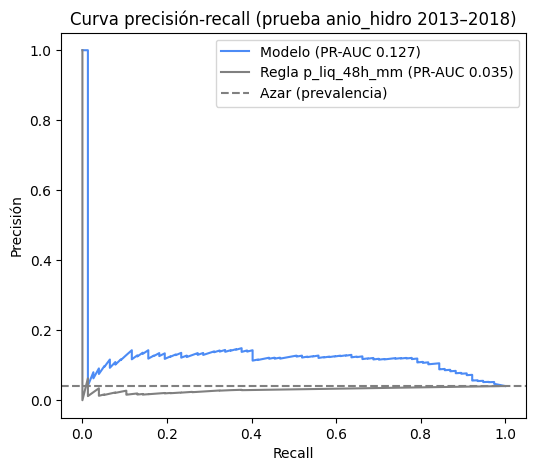

In [13]:
# meta 4: gráfico curva precisión-recall
fig, ax = plt.subplots(figsize=(6, 5))
for nombre, score, color in [("Modelo", prob, "#4C8BF5"), ("Regla p_liq_48h_mm", regla, "gray")]:
    p, r, _ = precision_recall_curve(y_te, score)
    ax.plot(r, p, color=color, label=f"{nombre} (PR-AUC {pr_auc(y_te, score):.3f})")
ax.axhline(y_te.mean(), ls="--", color="gray", label="Azar (prevalencia)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title("Curva precisión-recall (prueba anio_hidro 2013–2018)")
ax.legend()
plt.show()


                    modelo  regla   azar  eventos  dias
temporada                                              
verano (oct–mar)     0.138  0.069  0.079       68   863
invierno (abr–sep)   0.011  0.017  0.009        9  1037


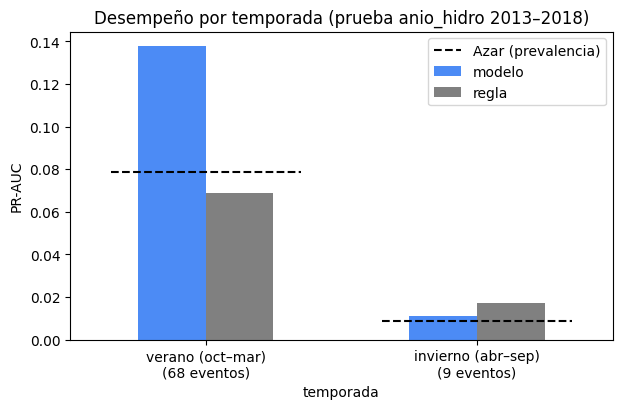

In [14]:
# meta 4: verano vs invierno (año completo: verano oct–mar, invierno abr–sep)
TEMPORADAS = {"verano (oct–mar)": [10, 11, 12, 1, 2, 3], "invierno (abr–sep)": [4, 5, 6, 7, 8, 9]}
filas = []
for temporada, meses in TEMPORADAS.items():
    dias = test.mes.isin(meses).to_numpy()
    filas.append({"temporada": temporada, "modelo": pr_auc(y_te[dias], prob[dias]),
                  "regla": pr_auc(y_te[dias], regla[dias]), "azar": y_te[dias].mean(),
                  "eventos": y_te[dias].sum(), "dias": dias.sum()})
estac = pd.DataFrame(filas).set_index("temporada")
print(estac.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
estac[["modelo", "regla"]].plot.bar(ax=ax, rot=0, color=["#4C8BF5", "gray"])
ax.set_xticks(range(len(estac)), [f"{t}\n({e} eventos)" for t, e in estac["eventos"].items()])
for i, azar in enumerate(estac["azar"]):
    ax.hlines(azar, i - 0.35, i + 0.35, color="black", linestyle="--", linewidth=1.5,
              label="Azar (prevalencia)" if i == 0 else None)
ax.set_ylabel("PR-AUC")
ax.set_title("Desempeño por temporada (prueba anio_hidro 2013–2018)")
ax.legend()
plt.show()


In [15]:
# meta 4: ¿la ventaja depende de un año? eventos por año y bootstrap por año hidrológico del test
print("Eventos > p95 por año hidrológico del test:", y_te.groupby(test.anio_hidro).sum().to_dict())
rng = np.random.default_rng(0)
anios_test = test.anio_hidro.unique()
filas_anio = {a: np.flatnonzero(test.anio_hidro.to_numpy() == a) for a in anios_test}
dif = []
for _ in range(2000):  # se remuestrean años completos: días del mismo año están correlacionados
    idx = np.concatenate([filas_anio[a] for a in rng.choice(anios_test, len(anios_test))])
    if y_te.iloc[idx].sum():
        dif.append(pr_auc(y_te.iloc[idx], prob[idx]) - pr_auc(y_te.iloc[idx], regla.iloc[idx]))
ic_bajo, ic_alto = np.percentile(dif, [2.5, 97.5])
sin_2014 = test.anio_hidro.ne(2014).to_numpy()
print(f"Modelo - regla: {pr_auc(y_te, prob) - pr_auc(y_te, regla):+.3f} | IC 95 % por año [{ic_bajo:+.3f}, {ic_alto:+.3f}] | "
      f"sin 2014: modelo {pr_auc(y_te[sin_2014], prob[sin_2014]):.3f} vs regla {pr_auc(y_te[sin_2014], regla[sin_2014]):.3f}")


Eventos > p95 por año hidrológico del test: {2013: 5, 2014: 35, 2015: 11, 2016: 7, 2017: 19, 2018: 0}


Modelo - regla: +0.092 | IC 95 % por año [+0.023, +0.225] | sin 2014: modelo 0.106 vs regla 0.027


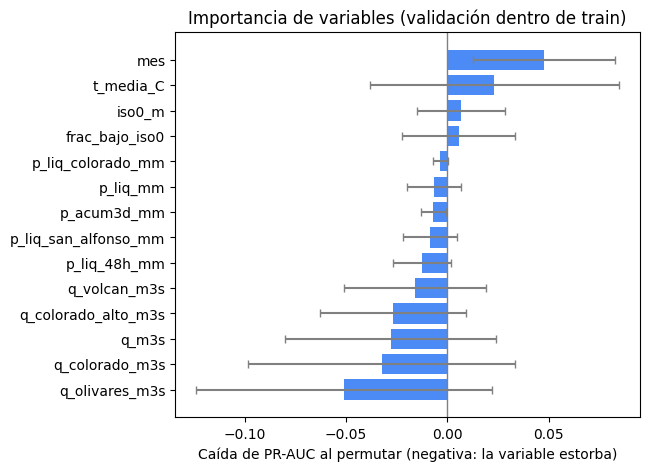

In [16]:
# meta 4: importancia de variables SIN mirar el test: permutación en los folds de validación de train
imp_folds = []
for tr, va in GroupKFold(n_splits=5).split(train, y_tr, groups=train.anio_hidro):
    m = RandomForestClassifier(**RF).fit(train[FEATS].iloc[tr], y_tr.iloc[tr])
    imp_folds.append(permutation_importance(m, train[FEATS].iloc[va], y_tr.iloc[va], scoring="average_precision",
                                            n_repeats=5, random_state=0).importances_mean)
imp_folds = pd.DataFrame(imp_folds, columns=FEATS)
imp_s = imp_folds.mean().sort_values()
imp_std_s = imp_folds.std().loc[imp_s.index]  # variación entre folds (años distintos)
fig, ax = plt.subplots(figsize=(6, 5))
ax.barh(imp_s.index, imp_s.values, xerr=imp_std_s.values, color="#4C8BF5",
        ecolor="gray", capsize=3)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Caída de PR-AUC al permutar (negativa: la variable estorba)")
ax.set_title("Importancia de variables (validación dentro de train)")
plt.show()


In [17]:
# meta 4: ¿qué grupo de variables aporta? ablación con la misma validación cruzada (solo train)
GRUPOS = {
    "caudales": [f for f in FEATS if f.startswith("q_")],
    "lluvia": ["p_liq_mm", "p_liq_48h_mm", "p_acum3d_mm", "p_liq_colorado_mm", "p_liq_san_alfonso_mm"],
    "temperatura e isoterma": ["iso0_m", "frac_bajo_iso0", "t_media_C"],
    "mes": ["mes"],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(FEATS)
ablacion = pd.Series({"todas": cv["RF"], **{
    f"sin {grupo}": pr_auc_cv(RandomForestClassifier(**RF), [f for f in FEATS if f not in cols])
    for grupo, cols in GRUPOS.items()}})
print("PR-AUC validación cruzada (solo train):")
print(ablacion.round(3).to_string())
sin_caudales = [f for f in FEATS if f not in GRUPOS["caudales"]]
prob_sin_caudales = RandomForestClassifier(**RF).fit(train[sin_caudales], y_tr).predict_proba(test[sin_caudales])[:, 1]
print(f"Test sin caudales: {pr_auc(y_te, prob_sin_caudales):.3f} (modelo de la guía {pr_auc(y_te, prob):.3f}, "
      f"regla {pr_auc(y_te, regla):.3f})")

# física: con el mismo caudal, el río trae mucho más sedimento desde 2011 -> lo aprendido hasta 2012 no se traslada
c = t.dropna(subset=["q_m3s"])
cambio = (c.assign(tramo_q=pd.cut(c.q_m3s, [0, 60, 100, 150, 1000]),
                   periodo=np.where(c.anio_hidro <= 2010, "2000-2010", "2011-2018"),
                   extremo=c.ssc_mgL > umbral)
          .groupby(["tramo_q", "periodo"], observed=True)
          .agg(dias=("ssc_mgL", "size"), ssc_mediana=("ssc_mgL", "median"), prob_extremo=("extremo", "mean"))
          .unstack("periodo"))
print("\nRelación caudal–sedimento antes y después de 2011 (por tramo de q_m3s, m3/s):")
print(cambio.round(3).to_string())

# pronóstico: todas las variables del día anterior (disponibles antes de la muestra de las 08:00)
assert df.fecha.diff().dropna().dt.days.eq(1).all()  # un día por fila, en orden: shift(1) = ayer
AYER = [f for f in FEATS if f != "mes"]
ayer = df[AYER].shift(1).add_suffix("_ayer")
feats_ayer = [f + "_ayer" for f in AYER] + ["mes"]
prob_ayer = (RandomForestClassifier(**RF).fit(train.join(ayer)[feats_ayer], y_tr)
             .predict_proba(test.join(ayer)[feats_ayer])[:, 1])
print(f"\nPronóstico con datos de ayer: test {pr_auc(y_te, prob_ayer):.3f} "
      f"(regla con lluvia de ayer y anteayer {pr_auc(y_te, test.join(ayer).p_liq_48h_mm_ayer):.3f})")


PR-AUC validación cruzada (solo train):
todas                         0.184
sin caudales                  0.293
sin lluvia                    0.203
sin temperatura e isoterma    0.130
sin mes                       0.152


Test sin caudales: 0.140 (modelo de la guía 0.127, regla 0.035)

Relación caudal–sedimento antes y después de 2011 (por tramo de q_m3s, m3/s):
                 dias           ssc_mediana           prob_extremo          
periodo     2000-2010 2011-2018   2000-2010 2011-2018    2000-2010 2011-2018
tramo_q                                                                     
(0, 60]           581       982      60.000   129.035        0.002     0.004
(60, 100]        1055       785      70.280   260.390        0.001     0.057
(100, 150]        607       399     261.540   752.340        0.025     0.175
(150, 1000]       648       180     561.775   673.460        0.131     0.133



Pronóstico con datos de ayer: test 0.119 (regla con lluvia de ayer y anteayer 0.036)


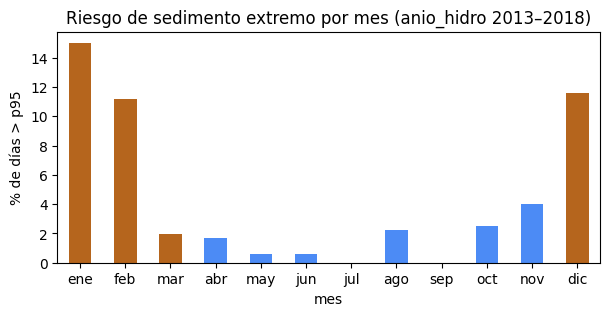

In [18]:
# meta 4: eventos por mes (por qué la regla de lluvia falla)
riesgo = test.assign(evento=y_te).groupby("mes").evento.mean() * 100
meses_es = {1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun",
            7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov", 12: "dic"}
colores = ["#B5651D" if mes in (12, 1, 2, 3) else "#4C8BF5" for mes in riesgo.index]
ax = riesgo.plot.bar(figsize=(7, 3), rot=0, color=colores)
ax.set_xticks(range(len(riesgo)), [meses_es[mes] for mes in riesgo.index])
ax.set_ylabel("% de días > p95")
ax.set_title("Riesgo de sedimento extremo por mes (anio_hidro 2013–2018)")
plt.show()


In [19]:
# chequeo: reglas de /auditar (sin fuga, partición temporal honesta)
PROHIBIDAS = {"ssc_mgL", "ssc_colorado_mgL", "ssc_san_alfonso_mgL", "ssc_hora_h", "ssc_pico_estimado_mgL",
              "evento_documentado", "evento_causa", "evento_fuente", "duracion_evento_h", "iso0_reportada_m"}
assert not PROHIBIDAS & set(FEATS), f"fuga en X: {PROHIBIDAS & set(FEATS)}"
assert train.anio_hidro.max() <= 2012 and test.anio_hidro.between(2013, 2018).all()
assert not set(train.fecha) & set(test.fecha), "días repetidos entre train y test"
print("Chequeos de auditoría OK")

Chequeos de auditoría OK


## Conclusiones de la Meta 4 (Random Forest, partición por `anio_hidro`: train <= 2012, test 2013–2018)

- **Global:** PR-AUC modelo 0.127 vs regla `p_liq_48h_mm` 0.035, con azar (prevalencia) 0.041. El modelo da ~3× el azar. La ventaja es robusta: remuestreando años completos del test, el IC 95 % de la diferencia es [+0.023, +0.225]. Ojo: 2014 concentra 35 de los 77 eventos del test, pero sin 2014 el modelo sigue ganando (0.106 vs 0.027).
- **Partición honesta:** antes se cortaba por año calendario y el verano 2012–13 (dic en train, ene–mar en test) quedaba partido. Días vecinos del mismo deshielo están muy correlacionados, así que el modelo "veía" parte del test. Con `anio_hidro` cada verano queda entero de un lado.
- **Verano (oct–mar):** modelo 0.138 vs regla 0.069 (azar 0.079). Aquí está toda la ventaja: los pulsos de deshielo dependen del calendario y de la temperatura (`mes` y `t_media_C` son las variables que más aportan en validación), no de la lluvia. Por eso la regla de lluvia queda incluso bajo el azar en verano.
- **Invierno (abr–sep):** modelo 0.011 **pierde** contra la regla (0.017), con solo 9 eventos (azar 0.009). Con tan pocos positivos el PR-AUC es muy ruidoso, y además la muestra de las 08:00 h (`ssc_hora_h`) se pierde los picos breves de las tormentas cálidas. Para invierno la regla física sigue siendo la mejor referencia.

### Elección del modelo: Random Forest
Se usa `RandomForestClassifier(n_estimators=500, min_samples_leaf=5)` por indicación de los organizadores, y la elección se valida sin mirar el test: con `GroupKFold` por `anio_hidro` dentro de train, RF da 0.184 vs `HistGradientBoostingClassifier` 0.176 (en el test: 0.127 vs 0.078). La ventaja en validación es chica; en el test es mayor, pero ese es un solo período de 6 años. `class_weight="balanced"` empeora la validación (0.166 vs 0.184): cambia cómo se ajusta el bosque y con eso el orden de las probabilidades, que es lo que mide PR-AUC.

### Los caudales no aportan: la relación caudal–sedimento cambió
La guía sugiere usar caudales, y el modelo principal los mantiene para seguirla. Pero medida sin mirar el test (permutación en los folds de validación), la importancia de los cinco caudales es negativa: estorban. Quitarlos sube la validación cruzada de 0.184 a 0.293 y el test de 0.127 a 0.140; quitar la temperatura y la isoterma, en cambio, la baja a 0.130.

La razón física está en la tabla de la celda de ablación: con el mismo caudal, el río trae mucho más sedimento desde 2011. Con 100–150 m³/s la mediana de SSC pasó de 262 a 752 mg/L y la probabilidad de superar el p95 de 2.5 % a 17.5 %; con 60–100 m³/s, de 0.1 % a 5.7 %. Solo sobre 150 m³/s la probabilidad se mantiene (13 %). Un modelo que aprende "cuánto sedimento trae cada caudal" hasta 2012 se equivoca después, mientras que el calendario y la temperatura del deshielo siguen funcionando igual. Por qué cambió la relación no se puede saber con estos datos (queda como pregunta para `/explorar`).

### Pronóstico, no solo nowcast
Los caudales y la meteorología del mismo día son promedios o totales diarios que incluyen horas posteriores a la muestra de las 08:00. Usando solo datos del día anterior, el modelo da 0.119 en el test (vs 0.127), frente a 0.036 de la regla con la lluvia de ayer y anteayer: la ventaja no depende de información posterior a la muestra.
